# 4. Spiking neurons and their exact mean field (Chapters 12–13)
200 θ-neurons with Lorentzian excitabilities, against the Montbrió–Pazó–Roxin equations $\dot r = \Delta/\pi + 2rv$, $\dot v = v^2 + \eta_0 + I - \pi^2r^2$.

**Picture first:** each neuron is a point running round a circle; the population is a density on the circle, crowded where the neurons are slow.

In [1]:
import numpy as np, matplotlib.pyplot as plt, pyxpp
plt.rcParams.update({"figure.figsize": (7, 4.2), "axes.spines.top": False, "axes.spines.right": False})
def load(name, **pars):
    m = pyxpp.load(text=open(f"ode/{name}.ode").read())
    if pars: m.set(**pars)
    return m

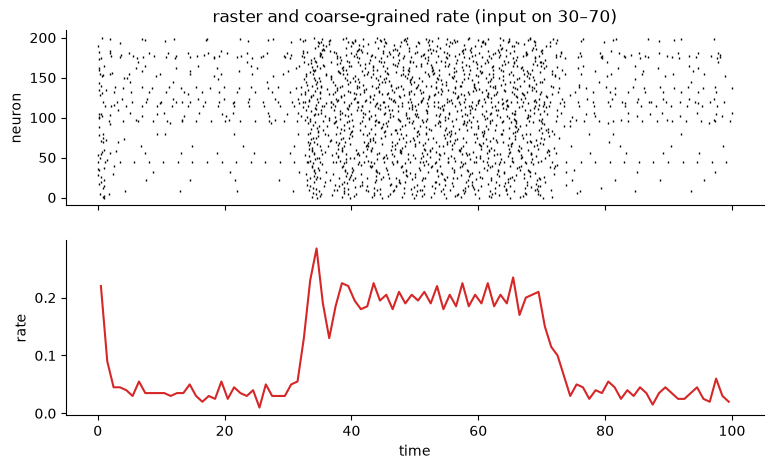

In [2]:
m = load('theta_network'); tr = m.run(total=100, dt=0.02)
t = np.asarray(tr.t); th = np.column_stack([tr[f'th{k}'] for k in range(1, 201)])
k = np.floor((th + np.pi)/(2*np.pi)); idx = np.argwhere(np.diff(k, axis=0) > 0)
sp = np.array([(t[i+1], j) for i, j in idx])
fig, axs = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
axs[0].plot(sp[:, 0], sp[:, 1], '|', ms=2, color='k'); axs[0].set_ylabel('neuron')
h, e = np.histogram(sp[:, 0], np.arange(0, 101, 1.0)); axs[1].plot(e[:-1]+0.5, h/200, 'C3')
axs[1].set_ylabel('rate'); axs[1].set_xlabel('time'); axs[0].set_title('raster and coarse-grained rate (input on 30–70)');

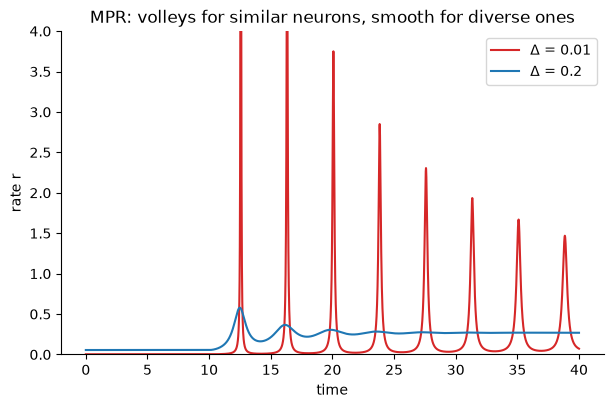

In [3]:
mf = load('mpr_mean_field')
for delta, c in [(0.01, 'C3'), (0.2, 'C0')]:
    r0 = np.sqrt(-0.3 + np.sqrt(0.09 + delta**2))/(np.pi*np.sqrt(2)); v0 = -delta/(2*np.pi*r0)
    mf.set(delta=delta, r=float(r0), v=float(v0)); tr = mf.run(total=40)
    plt.plot(tr.t, tr['r'], c, label=f'Δ = {delta}')
plt.ylim(0, 4); plt.xlabel('time'); plt.ylabel('rate r'); plt.legend(); plt.title('MPR: volleys for similar neurons, smooth for diverse ones');

**Try:** set `j=5` (recurrent excitation) in the MPR model and look for bistability between low and high rate.